# Exploratory Data Analysis on Retail Sales

**Intern:** Poleboina Kavya  
**Domain:** Data Analytics  
**Task:** Level 1 – Task 1: EDA on Retail Sales

## Objective
Explore 1,000 retail transactions to understand sales performance, customer demographics, product-category and price-point performance, and sales trends over time. The notebook ends with specific business recommendations.

## 1. Import libraries and load the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("retail_sales_dataset.csv")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


## 2. Inspect the data: shape, data types, null values

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[us]
 2   Customer ID       1000 non-null   str           
 3   Gender            1000 non-null   str           
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   str           
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[us](1), int64(5), str(3)
memory usage: 70.4 KB


In [3]:
print("Null values per column:")
df.isnull().sum()

Null values per column:


,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Transaction IDs:", df["Transaction ID"].duplicated().sum())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
df = df.drop_duplicates().copy()

Duplicate rows: 0
Duplicate Transaction IDs: 0
Date range: 2023-01-01 to 2024-01-01


**Observations**
- 1,000 rows and 9 columns. The data types are correct (`Date` is converted to datetime).
- There are **no null values and no duplicate rows**, so no cleaning is needed.
- The data runs from 1 Jan 2023 to 1 Jan 2024. **January 2024 contains only one day of sales**, so it is a partial month. I exclude it from the monthly and quarterly trend charts so that it does not look like a sales crash.

## 3. Descriptive statistics: mean, median, mode and standard deviation

In [5]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
stats = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "std": df[num_cols].std(),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
}).round(2)
stats

,mean,median,mode,std,min,max
Age,41.39,42.0,43.0,13.68,18,64
Quantity,2.51,3.0,4.0,1.13,1,4
Price per Unit,179.89,50.0,50.0,189.68,25,500
Total Amount,456.00,135.0,50.0,560.00,25,2000


**Observations**
- Average transaction value is **456**, but the median is **135**. A mean far above the median means the distribution is skewed by a group of high-value transactions.
- `Price per Unit` has a very large spread (std about 190): the values are only **25, 30, 50, 300 and 500**. This is a two-tier price structure (cheap items and premium items), not a smooth range of prices. The mode is 50 and the mean is about 180, which again shows the split.
- Customer ages run from 18 to 64 with a mean near 41.

## 4. Feature engineering

In [6]:
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")
df["Age Group"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 65],
                         labels=["18-25", "26-35", "36-45", "46-55", "56-64"])

# Complete months only: January 2024 has a single day of data
full = df[df["Date"] < "2024-01-01"]
df[["Date", "Month", "Quarter", "Age", "Age Group"]].head()

,Date,Month,Quarter,Age,Age Group
0,2023-11-24,2023-11,2023Q4,34,26-35
1,2023-02-27,2023-02,2023Q1,26,26-35
2,2023-01-13,2023-01,2023Q1,50,46-55
3,2023-05-21,2023-05,2023Q2,37,36-45
4,2023-05-06,2023-05,2023Q2,30,26-35


## 5. Key performance indicators

In [7]:
print("Total transactions     :", len(df))
print("Total units sold       :", df["Quantity"].sum())
print("Total revenue          :", df["Total Amount"].sum())
print("Average transaction    :", round(df["Total Amount"].mean(), 2))
print("Average customer age   :", round(df["Age"].mean(), 1))
print("Unique customers       :", df["Customer ID"].nunique())

Total transactions     : 1000
Total units sold       : 2514
Total revenue          : 456000
Average transaction    : 456.0
Average customer age   : 41.4
Unique customers       : 1000


## 6. Product analysis

,Total sales
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


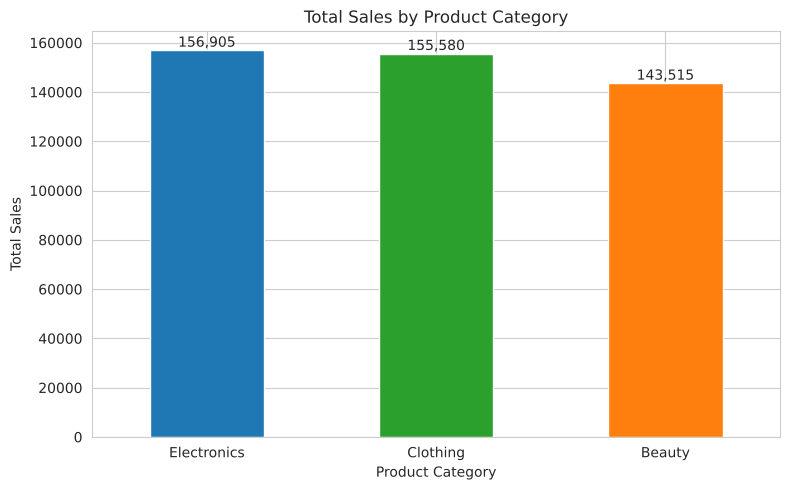

In [8]:
category_sales = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
display(category_sales.to_frame("Total sales"))

ax = category_sales.plot(kind="bar", figsize=(8, 5), color=["#1f77b4", "#2ca02c", "#ff7f0e"],
                         title="Total Sales by Product Category")
ax.set_xlabel("Product Category"); ax.set_ylabel("Total Sales")
for i, v in enumerate(category_sales.values):
    ax.text(i, v + 1500, f"{v:,}", ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("screenshots/sales_by_category.png", dpi=120)
plt.show()

**Observation:** Electronics (156,905), Clothing (155,580) and Beauty (143,515) are very close. Electronics leads Beauty by only 9%, so **no category dominates**. Revenue is spread almost evenly across the three.

,Item,Total Amount
0,Beauty @ 500,84500
1,Electronics @ 500,84500
2,Clothing @ 500,78500
3,Clothing @ 300,57900
4,Electronics @ 300,54900
5,Beauty @ 300,42600
6,Clothing @ 50,9450
7,Electronics @ 50,8750
8,Beauty @ 50,8500
9,Clothing @ 30,5130


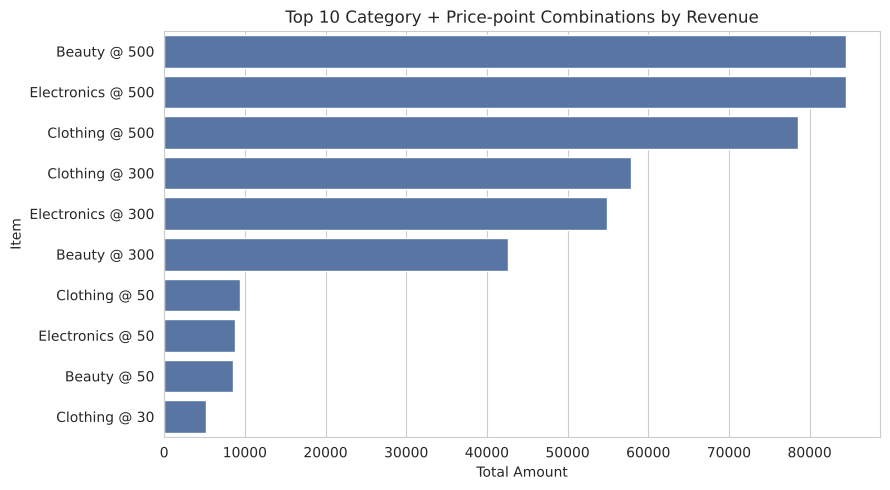

In [9]:
# The dataset has no individual product names, only 3 categories.
# As the closest substitute for "top 10 products", rank Category + Price-point combinations.
top10 = (df.groupby(["Product Category", "Price per Unit"])["Total Amount"].sum()
           .sort_values(ascending=False).head(10).reset_index())
top10["Item"] = top10["Product Category"] + " @ " + top10["Price per Unit"].astype(str)
display(top10[["Item", "Total Amount"]])

plt.figure(figsize=(9, 5))
sns.barplot(data=top10, y="Item", x="Total Amount", color="#4c72b0")
plt.title("Top 10 Category + Price-point Combinations by Revenue")
plt.tight_layout()
plt.savefig("screenshots/top10_items.png", dpi=120)
plt.show()

**Observation:** The dataset has no product names, only three categories, so a true "top 10 best-selling products" is not possible. I ranked Category + Price-point combinations instead. The top three are all price 500 items (Beauty and Electronics at 84,500 each, Clothing at 78,500), followed by the price 300 items. **Price point matters more than category.**

,Units sold
Product Category,
Clothing,894
Electronics,849
Beauty,771


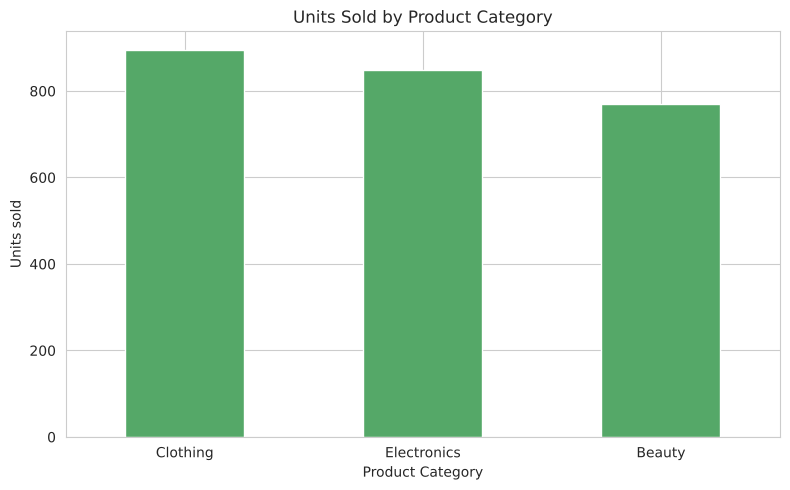

In [10]:
qty = df.groupby("Product Category")["Quantity"].sum().sort_values(ascending=False)
display(qty.to_frame("Units sold"))
ax = qty.plot(kind="bar", figsize=(8, 5), color="#55a868", title="Units Sold by Product Category")
ax.set_ylabel("Units sold"); plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("screenshots/quantity_by_category.png", dpi=120)
plt.show()

**Observation:** Clothing sells the most units (894) and Beauty the fewest (771), yet Beauty has the highest average transaction value (467.5 against 443.2 for Clothing). Clothing wins on volume, Beauty on value per sale.

## 7. Customer demographics

,transactions,total_sales,avg_sale
Gender,,,
Female,510,232840,456.5
Male,490,223160,455.4


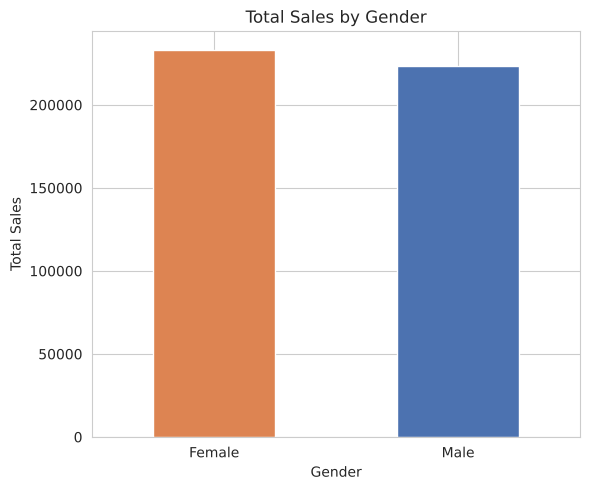

In [11]:
gender = df.groupby("Gender")["Total Amount"].agg(transactions="count", total_sales="sum", avg_sale="mean").round(1)
display(gender)
ax = gender["total_sales"].plot(kind="bar", figsize=(6, 5), color=["#dd8452", "#4c72b0"], title="Total Sales by Gender")
ax.set_ylabel("Total Sales"); plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("screenshots/sales_by_gender.png", dpi=120)
plt.show()

**Observation:** Female customers account for 232,840 in sales (51%) and male customers for 223,160 (49%). The average spend per transaction is almost identical (**456.5 vs 455.4**). The small gap comes from 20 more female transactions, not from higher spending, so **gender is not a useful basis for targeting**.

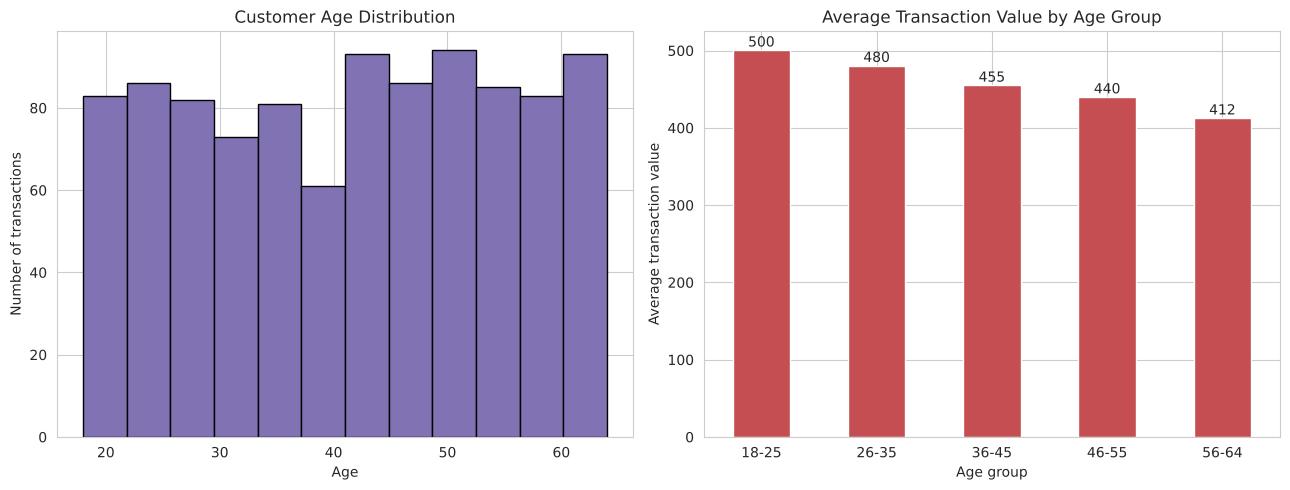

,transactions,total_sales,avg_sale
Age Group,,,
18-25,169,84550,500.3
26-35,205,98480,480.4
36-45,202,91870,454.8
46-55,229,100690,439.7
56-64,195,80410,412.4


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
df["Age"].plot(kind="hist", bins=12, edgecolor="black", color="#8172b3", ax=axes[0], title="Customer Age Distribution")
axes[0].set_xlabel("Age"); axes[0].set_ylabel("Number of transactions")

ag = df.groupby("Age Group", observed=True)["Total Amount"].mean()
ag.plot(kind="bar", color="#c44e52", ax=axes[1], title="Average Transaction Value by Age Group")
axes[1].set_ylabel("Average transaction value"); axes[1].set_xlabel("Age group"); axes[1].tick_params(axis="x", rotation=0)
for i, v in enumerate(ag.values):
    axes[1].text(i, v + 5, f"{v:.0f}", ha="center")
plt.tight_layout()
plt.savefig("screenshots/customer_age_distribution.png", dpi=120)
plt.show()

df.groupby("Age Group", observed=True)["Total Amount"].agg(transactions="count", total_sales="sum", avg_sale="mean").round(1)

**Observations**
- Customers are spread fairly evenly across all ages from 18 to 64. The **46-55 group is the largest** (229 transactions, 100,690 in sales).
- Average spend per transaction **falls steadily with age**: 500 for ages 18-25 down to 412 for ages 56-64. Younger customers spend about 21% more per purchase.

## 8. Sales trends over time

,Monthly sales
Month,
2023-01,35450
2023-02,44060
2023-03,28990
2023-04,33870
2023-05,53150
2023-06,36715
2023-07,35465
2023-08,36960
2023-09,23620


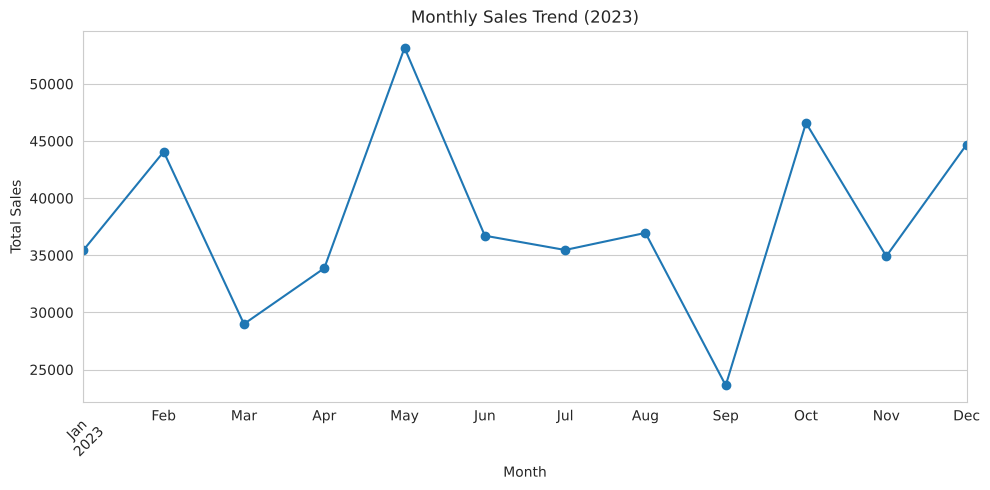

In [13]:
monthly = full.groupby("Month")["Total Amount"].sum()
display(monthly.to_frame("Monthly sales"))

ax = monthly.plot(kind="line", marker="o", figsize=(10, 5), color="#1f77b4", title="Monthly Sales Trend (2023)")
ax.set_xlabel("Month"); ax.set_ylabel("Total Sales")
peak = monthly.idxmax()
ax.annotate(f"Peak: {monthly.max():,}", xy=(list(monthly.index).index(peak), monthly.max()),
            xytext=(0, 12), textcoords="offset points", ha="center")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("screenshots/monthly_sales_trend.png", dpi=120)
plt.show()

**Observation:** Monthly sales swing between **23,620 (September, the lowest)** and **53,150 (May, the highest)**. There is no steady upward or downward trend. Peaks in February, May, October and December alternate with dips in March, April and September.

,Quarterly sales
Quarter,
2023Q1,108500
2023Q2,123735
2023Q3,96045
2023Q4,126190




In [14]:
quarterly = full.groupby("Quarter")["Total Amount"].sum()
display(quarterly.to_frame("Quarterly sales"))

ax = quarterly.plot(kind="bar", figsize=(8, 5), color="#55a868", title="Quarterly Sales (2023)")
ax.set_ylabel("Total Sales"); ax.set_xlabel("Quarter"); plt.xticks(rotation=0)
for i, v in enumerate(quarterly.values):
    ax.text(i, v + 1500, f"{v:,}", ha="center")
plt.tight_layout()
plt.savefig("screenshots/quarterly_sales_trend.png", dpi=120)
plt.show()

**Observation:** Q4 is the strongest quarter (126,190) and Q2 is second (123,735). **Q3 is the weakest (96,045), about 24% below Q4**, driven by the September dip.

## 9. Correlation heatmap

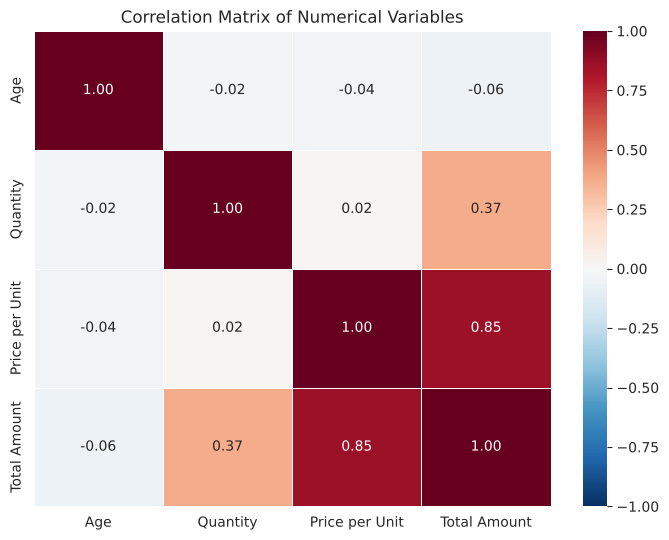

In [15]:
corr = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.savefig("screenshots/correlation_heatmap.png", dpi=120)
plt.show()

**Observations**
- **Price per Unit has a strong correlation with Total Amount (0.85)**. Quantity has a moderate one (0.37).
- Age has almost no correlation with anything (between -0.06 and -0.02). Age alone does not drive how much a customer buys.
- Price and quantity are not related to each other (0.02), so customers do not buy fewer units of expensive items.

## 10. Additional insight: a few price points drive most of the revenue

Items priced 300 or 500: 39.6% of transactions -> 88.4% of revenue


,transactions,revenue,% of transactions,% of revenue
Price per Unit,,,,
25,210,13050,21.0,2.9
30,183,13350,18.3,2.9
50,211,26700,21.1,5.9
300,197,155400,19.7,34.1
500,199,247500,19.9,54.3


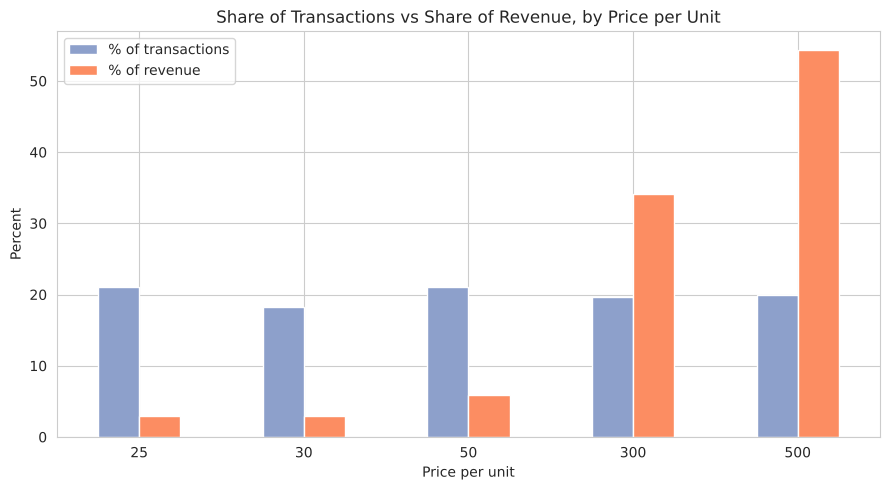

In [16]:
pp = df.groupby("Price per Unit").agg(transactions=("Total Amount", "count"), revenue=("Total Amount", "sum"))
pp["% of transactions"] = (pp["transactions"] / pp["transactions"].sum() * 100).round(1)
pp["% of revenue"] = (pp["revenue"] / pp["revenue"].sum() * 100).round(1)
display(pp)

ax = pp[["% of transactions", "% of revenue"]].plot(kind="bar", figsize=(9, 5), color=["#8da0cb", "#fc8d62"],
                                                   title="Share of Transactions vs Share of Revenue, by Price per Unit")
ax.set_ylabel("Percent"); ax.set_xlabel("Price per unit"); plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("screenshots/price_point_share.png", dpi=120)
plt.show()

premium = df[df["Price per Unit"] >= 300]
print(f"Items priced 300 or 500: {len(premium)/len(df)*100:.1f}% of transactions -> {premium['Total Amount'].sum()/df['Total Amount'].sum()*100:.1f}% of revenue")

**Observation (the non-obvious finding):** Every price point is bought about equally often (18-21% of transactions each), but they are not equal in revenue. The two premium price points (300 and 500) are **39.6% of transactions and 88.4% of revenue**. The price 500 items alone bring in 54.3% of revenue. The three cheapest price points (25, 30, 50) are 60% of transactions and only 11.6% of revenue.

I also checked basket size. Average transaction value rises with quantity: 177 for 1 unit, 334 for 2, 599 for 3 and 707 for 4 units.

## 11. Findings and conclusion

**Summary of findings**
- 1,000 transactions, total revenue **456,000**, 2,514 units, average transaction **456**. The data is clean (no nulls, no duplicates).
- The three categories earn almost the same revenue. **Price point, not category, drives revenue**: items priced 300 and 500 are 39.6% of transactions and 88.4% of revenue.
- Men and women spend the same per transaction. Younger customers spend more per transaction (500 at ages 18-25 vs 412 at 56-64).
- Sales are seasonal and uneven: Q4 strongest (126,190), Q3 weakest (96,045), September the lowest month and May the highest.

**Business recommendations**
1. **Prioritise premium stock and promotion.** Items at 300 and 500 produce 88% of revenue from under 40% of transactions. Keep these in stock, feature them on the home page and in ads, and review whether the cheap items at 25 and 30 (together only 5.8% of revenue) deserve the shelf space they take.
2. **Target by age, not by gender.** Gender shows no spending difference (456.5 vs 455.4), so gender-based campaigns are not justified. Ages 18-25 spend the most per purchase, so run premium and bundle offers for them. Ages 46-55 are the largest revenue group (100,690), so give them loyalty offers, especially on Electronics, which is strongest for ages 36 and over.
3. **Fix the September slump and prepare for peak months.** September (23,620) is less than half of May (53,150), and Q3 is 24% below Q4. Run a September promotion or a back-to-school/festival campaign, and stock up ahead of the May, October and December peaks.
4. **Push bigger baskets.** Average spend rises from 177 (1 unit) to 707 (4 units). Multi-buy offers such as "buy 3, save" should lift revenue per transaction.

**Limitations.** The data covers one year and 1,000 transactions, with no product names, so patterns are descriptive and should not be read as proof of cause and effect. January 2024 has only one day of data and was excluded from the trend charts.